# Widgets: glidebrytere og knapper

Widgets vises under cellen, og når du endrer dem, kjører Python på nytt. Navnene er de samme som i **ipywidgets**, så koden virker også i Google Colab og Jupyter.

Kjør cellene med **Shift+Enter**, og dra i glidebryterne.

In [1]:
import cv2
import ipywidgets as widgets
from ipywidgets import interact

img = cv2.imread("nature.png")   # fra mappen bilder/
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

## interact

`@interact` lager en widget for hvert argument: `(0, 255)` blir en glidebryter, `True`/`False` en avkrysningsboks og en liste en nedtrekksliste. Funksjonen kjører hver gang du endrer noe.

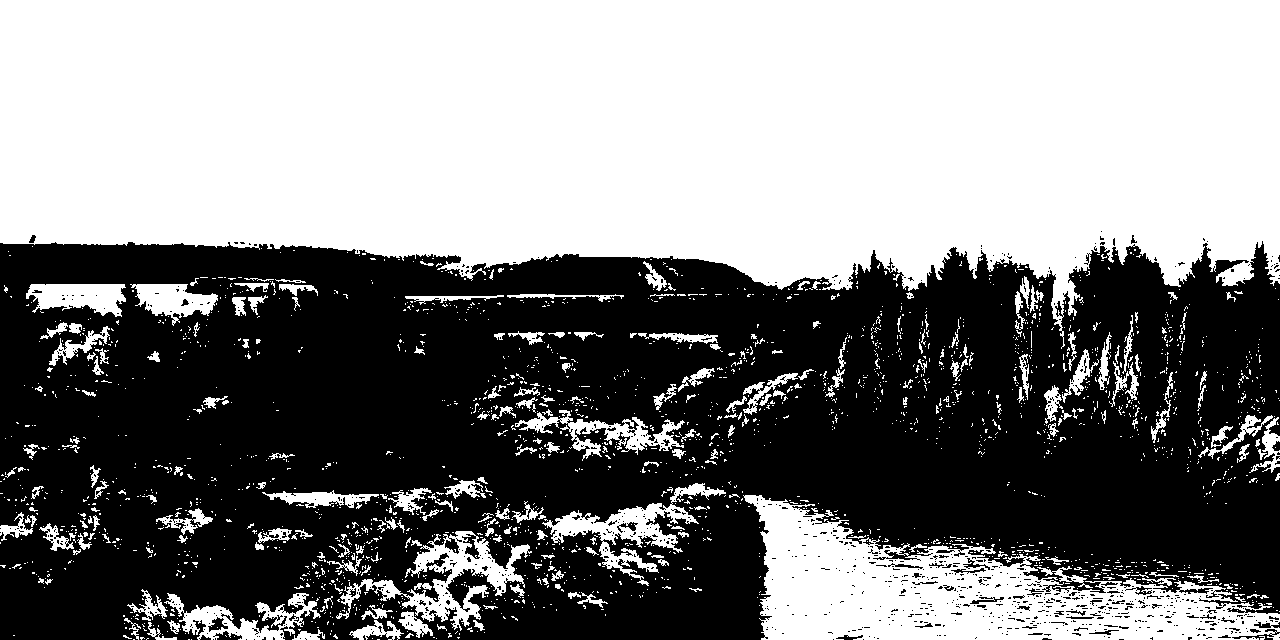

In [2]:
@interact(thresh=(0, 255), inverter=False, metode=["THRESH_BINARY", "THRESH_TRUNC", "THRESH_TOZERO"])
def terskel(thresh=127, inverter=False, metode="THRESH_BINARY"):
    typ = getattr(cv2, metode)
    if inverter and metode == "THRESH_BINARY":
        typ = cv2.THRESH_BINARY_INV
    _, ut = cv2.threshold(gray, thresh, 255, typ)
    cv2.imshow("resultat", ut)

## Trackbar som i OpenCV

`cv2.createTrackbar` blir en glidebryter, og callbacken kjører når du drar i den. `cv2.imshow` med samme vindusnavn bytter ut bildet, som i et vanlig OpenCV-vindu.

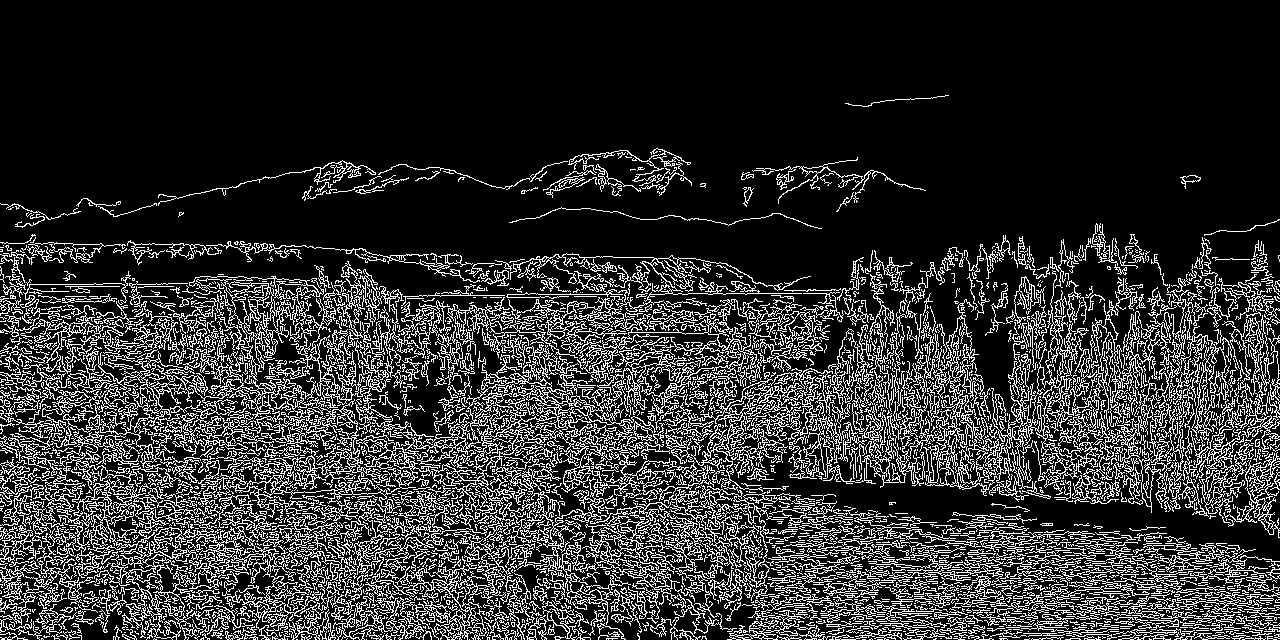

In [3]:
def kanter(_):
    lav = cv2.getTrackbarPos("lav", "Canny")
    hoy = cv2.getTrackbarPos("høy", "Canny")
    cv2.imshow("Canny", cv2.Canny(gray, lav, hoy))

cv2.namedWindow("Canny")
cv2.createTrackbar("lav", "Canny", 50, 255, kanter)
cv2.createTrackbar("høy", "Canny", 150, 255, kanter)
kanter(0)

## Knapper og Output

Med enkeltwidgets bestemmer du selv hva som skjer. `on_click` kjører en funksjon når du trykker på knappen, og `observe` når en verdi endres. Det som skrives ut inne i `with ut:`, havner i Output-området.

In [4]:
farge = widgets.ColorPicker(value="#2257dd", description="Farge")
tykkelse = widgets.IntSlider(value=8, min=1, max=40, description="Tykkelse")
tegn = widgets.Button(description="Tegn en sirkel", button_style="primary")
ut = widgets.Output()

def tegn_sirkel(_):
    r, g, b = (int(farge.value[i:i + 2], 16) for i in (1, 3, 5))
    bilde = img.copy()
    cv2.circle(bilde, (240, 160), 100, (b, g, r), tykkelse.value)
    with ut:
        ut.clear_output(wait=True)
        print("BGR", (b, g, r))
        cv2.imshow("sirkel", bilde)

tegn.on_click(tegn_sirkel)
display(widgets.VBox([farge, tykkelse, tegn]), ut)